# From next-character prediction to name generation

A companion to Lectures 14 and 15

Marcel Turcotte  
2026-11-05

How could a classifier invent a name? Instead of asking it to choose a
complete name, ask it to predict **one character at a time**. Its output
is a distribution over possible next characters. Sampling from that
distribution repeatedly turns the classifier into a generator.

This self-study notebook connects Lecture 14’s multiclass classification
and cross-entropy to Lecture 15’s one-dimensional convolutions. We first
train a feedforward neural network, then replace its first layer with
`Conv1D`. Both models use the same examples, objective, training budget,
and generation code.

By the end, you should be able to construct next-character training
examples, explain autoregressive generation, distinguish training from
sampling, and describe how context length and temperature affect the
result.

## A research foundation: neural probabilistic language models

<a href="https://www.jmlr.org/papers/v3/bengio03a.html" class="external"
data-icon="true">Bengio, Ducharme, Vincent, and Jauvin (2003)</a>
developed an influential **neural probabilistic language model**. Their
feedforward network takes a fixed number of preceding **words**, looks
up a learned vector for each word, concatenates those vectors, and
predicts a softmax distribution over the next word. Training jointly
learns the word vectors and the prediction network by increasing the
probability assigned to observed text.

The learned word vectors are **distributed representations**: a word is
described by several learned numerical coordinates. Sharing this
representation across contexts helps the model generalize beyond exact
word sequences seen during training. This is a central contribution of
the paper.

Our feedforward model follows its **fixed-context neural prediction
principle**, with deliberate simplifications. We predict characters
rather than words, use fixed one-hot character vectors rather than
learned word embeddings, and use a ReLU hidden layer rather than the
paper’s `tanh` layer. This is a teaching adaptation, rather than a
reproduction of the original architecture or results. An embedding layer
would be a natural later extension: it replaces each token’s one-hot
vector with a learned vector selected from a shared matrix.

## Preparation

Run this notebook from a fresh kernel, in order. It requires NumPy,
Matplotlib, and TensorFlow with Keras. The setup selects **TensorFlow as
the Keras backend** before importing the framework. Training is small
enough to explore on a CPU; the measured time will depend on the
machine.

In [1]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

from pathlib import Path
from time import perf_counter

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

SEED = 42
CONTEXT_LENGTH = 8
HIDDEN_UNITS = 128
FILTERS = 32
KERNEL_SIZE = 3
EPOCHS = 12
BATCH_SIZE = 256
LEARNING_RATE = 0.003

keras.utils.set_random_seed(SEED)
print(f"TensorFlow {tf.__version__}; Keras backend: {keras.backend.backend()}")

TensorFlow 2.21.0; Keras backend: tensorflow

## Names as a training corpus

We use the names file from Andrej Karpathy’s
<a href="https://github.com/karpathy/makemore" class="external"
data-icon="true">makemore project</a>. Its README attributes the names
to US Social Security Administration data for 2018. The file contains
32,033 entries, including repeated names. These are a particular
collection of spellings, rather than a representative sample of all
names or languages. Each distinct spelling is included once; longer
names contribute more next-character targets. We are not modeling
population frequencies.

The course copy is in `data/makemore_names.txt`. If the notebook is
downloaded without that file, Keras downloads it into the current
directory’s `data` folder. A fixed repository revision and SHA-256
checksum identify the data.

In [2]:
DATA_URL = (
    "https://raw.githubusercontent.com/karpathy/makemore/"
    "988aa59e4d8fefa526d06f3b453ad116258398d4/names.txt"
)
DATA_HASH = "0a30b5557f192f32ab962680889aac5f6fda0f4cecf40a6d0b5694f58ea8cc4d"
data_path = keras.utils.get_file(
    fname="makemore_names.txt", origin=DATA_URL, file_hash=DATA_HASH,
    cache_dir=".", cache_subdir="data"
)
raw_names = Path(data_path).read_text(encoding="utf-8").splitlines()
names = np.array(sorted(set(raw_names)))

rng = np.random.default_rng(SEED)
names = rng.permutation(names)
train_end = int(0.8 * len(names))
valid_end = int(0.9 * len(names))
train_names = names[:train_end]
valid_names = names[train_end:valid_end]
test_names = names[valid_end:]

print(f"File entries: {len(raw_names):,}; distinct names: {len(names):,}")
print(f"Whole-name split: {len(train_names):,} training, "
      f"{len(valid_names):,} validation, {len(test_names):,} test")
print("Some training names:", ", ".join(train_names[:12]))

File entries: 32,033; distinct names: 29,494
Whole-name split: 23,595 training, 2,949 validation, 2,950 test
Some training names: tayma, adaiah, sirus, camilla, universe, carlynn, airabella, alakai, cowan, leighland, yenifer, penny

We remove duplicates and split **whole names before constructing
windows**. Otherwise, different overlapping windows from the same name
could occur in both training and evaluation data. Validation loss helps
us inspect learning; the test set is reserved for the final comparison.
The twelve-epoch budget and both architectures are specified in advance.

## A token, a context, and a target

A **token** is one unit in the sequence. Here, tokens are lowercase
letters plus a boundary symbol, `.`. The vocabulary is fixed in advance,
so it does not need to be learned from the held-out names. Character IDs
are labels, with no meaningful numerical distance between them.

At the beginning of a name, we fill the context with boundary symbols.
During training, a boundary symbol **as a target** means that the name
has ended. During generation, sampling it stops the name. The same
symbol serves both purposes, as in many character-level names examples.

For example, with a three-character context, `emma` supplies five
examples:

| Context | Target |
|---------|--------|
| `...`   | `e`    |
| `..e`   | `m`    |
| `.em`   | `m`    |
| `emm`   | `a`    |
| `mma`   | `.`    |

Each name supplies one target per letter plus an end target. The text
itself supplies the labels: **self-supervised learning** creates a
prediction task from observed data without separately annotating the
desired next token.

In [3]:
vocabulary = ".abcdefghijklmnopqrstuvwxyz"
VOCAB_SIZE = len(vocabulary)
char_to_id = {char: index for index, char in enumerate(vocabulary)}

def make_examples(words, context_length):
    contexts, targets = [], []
    for word in words:
        context = [0] * context_length
        for char in word + ".":
            target = char_to_id[char]
            contexts.append(context)
            targets.append(target)
            context = context[1:] + [target]
    return np.asarray(contexts, dtype="int32"), np.asarray(targets, dtype="int32")

example_contexts, example_targets = make_examples(["emma"], 3)
for context, target in zip(example_contexts, example_targets):
    print("".join(vocabulary[index] for index in context), "->", vocabulary[target])

train_contexts, y_train = make_examples(train_names, CONTEXT_LENGTH)
valid_contexts, y_valid = make_examples(valid_names, CONTEXT_LENGTH)
test_contexts, y_test = make_examples(test_names, CONTEXT_LENGTH)

one_hot = np.eye(VOCAB_SIZE, dtype="float32")
X_train = one_hot[train_contexts]
X_valid = one_hot[valid_contexts]
X_test = one_hot[test_contexts]
print("Training inputs:", X_train.shape, "Targets:", y_train.shape)

... -> e
..e -> m
.em -> m
emm -> a
mma -> .
Training inputs: (168962, 8, 27) Targets: (168962,)

Each input has shape `(8, 27)`: eight positions, each with 27 character
channels. One channel is 1 at each position, and the others are 0. A
batch has shape `(batch_size, 8, 27)`. This is the same one-hot sequence
representation used for the four nucleotide channels in the
biological-sequence companion.

We may shuffle training windows because each window is a complete
prediction example. The order **within** each window is preserved.

## Feedforward prediction

The first model flattens the context into a vector, computes a ReLU
hidden layer, and returns one **logit**, or unnormalized score, for each
possible next character. Flattening retains the order through the fixed
vector positions.

The training loss for an observed target character $c_t$ is

$$
\ell_t = -\log p_\theta(c_t \mid c_{t-k},\ldots,c_{t-1}),
$$

where $k$ is the context length and $\theta$ contains the network’s
parameters. The mean loss $J$ averages over training targets. Assigning
greater probability to the observed next character lowers the loss.

`SparseCategoricalCrossentropy` accepts integer class IDs as targets.
With `from_logits=True`, Keras combines softmax and cross-entropy
stably. There is no separate softmax layer during training. Keras
computes the gradients and Adam uses them to update the parameters;
NumPy prepares the examples.

In [4]:
mlp = keras.Sequential([
    keras.layers.Input(shape=(CONTEXT_LENGTH, VOCAB_SIZE)),
    keras.layers.Flatten(),
    keras.layers.Dense(HIDDEN_UNITS, activation="relu"),
    keras.layers.Dense(VOCAB_SIZE)
], name="feedforward")

def train_model(model):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True)
    )
    start = perf_counter()
    history = model.fit(
        X_train, y_train, validation_data=(X_valid, y_valid),
        epochs=EPOCHS, batch_size=BATCH_SIZE, shuffle=True, verbose=0
    )
    print(f"{model.name}: {model.count_params():,} parameters; "
          f"{perf_counter() - start:.1f} s training")
    return history

mlp_history = train_model(mlp)

feedforward: 31,259 parameters; 6.0 s training

## Inspect the next-character distribution

Before generating a complete name, inspect one prediction. Which
characters would you expect after `mar`? Several next characters can be
reasonable even though each training example has only one observed
target.

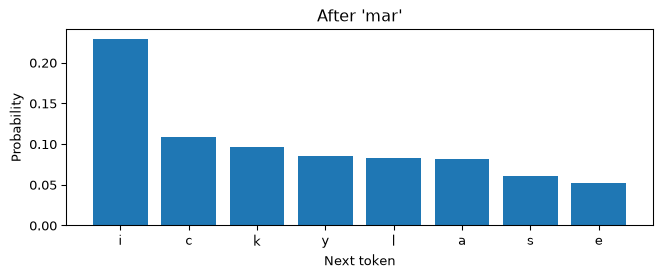

In [5]:
def next_probabilities(model, prefix, temperature=1.0):
    context = ([0] * CONTEXT_LENGTH + [char_to_id[char] for char in prefix])
    context = np.array([context[-CONTEXT_LENGTH:]], dtype="int32")
    logits = model(one_hot[context], training=False)
    probabilities = keras.ops.softmax(logits / temperature, axis=-1)
    return keras.ops.convert_to_numpy(probabilities)[0]

prefix = "mar"
probabilities = next_probabilities(mlp, prefix)
top = np.argsort(probabilities)[-8:][::-1]
labels = ["end" if vocabulary[index] == "." else vocabulary[index] for index in top]
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(labels, probabilities[top])
ax.set(xlabel="Next token", ylabel="Probability", title=f"After '{prefix}'")
fig.tight_layout()
plt.show()

## Autoregressive generation

An **autoregressive model** predicts each token from preceding tokens.
To generate a name, sample a next character, append it, and predict
again. The same trained network is reused at every step. Its parameters
remain fixed throughout generation.

During training, contexts contain observed letters from the data. During
generation, they also contain the model’s previous sampled letters. An
unfortunate prediction can therefore change all subsequent predictions.

The generation loop stops at `.` or at an explicit length limit. A
prefix prompts the model with an existing beginning; all prefix
characters must be lowercase letters from the vocabulary.

In [6]:
def generate_name(model, rng, prefix="", temperature=1.0, max_new_characters=24):
    name = prefix
    for _ in range(max_new_characters):
        probabilities = next_probabilities(model, name, temperature)
        token = rng.choice(VOCAB_SIZE, p=probabilities)
        if token == 0:
            return name, True
        name += vocabulary[token]
    return name, False

def show_samples(model, prefix="", temperature=1.0, count=12):
    rng = np.random.default_rng(SEED)
    samples = [generate_name(model, rng, prefix, temperature) for _ in range(count)]
    print(", ".join((name or "<empty>") + ("" if ended else " [length limit]")
                    for name, ended in samples))
    return samples

mlp_samples = show_samples(mlp)
print("\nContinuations of 'mar':")
show_samples(mlp, prefix="mar", count=6);

petrayco, jaynna, kavionnie, jafiry, gialiana, mattella, ashon, kairelli, kadelyn, akennie, rabar, brayleigh

Continuations of 'mar':
marritl, marymi, mariclio, mareles, marriyah, mariaan

## Sampling temperature

For logits $z_j$ and temperature $T>0$, the sampling probabilities are

$$
p_j(T)=\frac{\exp(z_j/T)}{\sum_i\exp(z_i/T)}.
$$

At $T=1$, we sample from the model’s predicted distribution. Lower
temperatures concentrate probability on high-scoring choices; higher
temperatures flatten the distribution. Temperature changes sampling,
without retraining the network. Greedy decoding always chooses a largest
logit; it is a separate deterministic decoding rule.

Before running the cell, predict which temperature will yield more
varied spellings. Does greater variety necessarily improve plausibility?

In [7]:
for temperature in (0.6, 1.0, 1.4):
    print(f"Temperature {temperature}:")
    show_samples(mlp, temperature=temperature, count=6)

Temperature 0.6:
mark, wilen, shera, arlien, marachin, dalani
Temperature 1.0:
petrayco, jaynna, kavionnie, jafiry, gialiana, mattella
Temperature 1.4:
rhyobync, jaynnbel, slonylia, adniya, jadien, soluth

## Introduce a one-dimensional convolution

The second model receives exactly the same `(8, 27)` inputs. A
width-three kernel examines three neighboring characters, across all 27
channels. Each filter reuses its weights at every valid position. With
32 filters and no padding, the resulting shape is `(6, 32)` for each
example.

`Flatten` preserves the locations of these responses before the Dense
layers combine them. A local pattern near the final character can
influence the prediction differently from the same pattern near the
start of the context. The Dense prediction head can use information from
the whole eight-character window, even though each individual
convolutional response sees three positions.

Every input window contains **only characters preceding its one
target**. Consequently, ordinary `padding="valid"` does not expose
future characters. If we instead predicted the next character at every
position of a complete sequence, we would need causal convolutions or
another constraint preventing each prediction from using later
characters. See the
<a href="https://keras.io/api/layers/convolution_layers/convolution1d/"
class="external" data-icon="true">Keras Conv1D documentation</a>.

In [8]:
keras.utils.set_random_seed(SEED)
cnn = keras.Sequential([
    keras.layers.Input(shape=(CONTEXT_LENGTH, VOCAB_SIZE)),
    keras.layers.Conv1D(FILTERS, KERNEL_SIZE, padding="valid", activation="relu"),
    keras.layers.Flatten(),
    keras.layers.Dense(HIDDEN_UNITS, activation="relu"),
    keras.layers.Dense(VOCAB_SIZE)
], name="convolutional")

cnn_history = train_model(cnn)
cnn_samples = show_samples(cnn)

convolutional: 30,811 parameters; 9.7 s training
pessatus, jaymon, kavir, yusek, anny, gianm, matteus, dega, roskel, angelise, alanna, darklynn

At the default settings, the MLP has 31,259 parameters and the CNN has
30,811. Both receive the same number of mini-batch updates. Their
internal computations and elapsed times differ. This is a focused
illustration of two architectures under similar budgets; one run cannot
establish that either is generally better.

## Follow learning and evaluate once

Cross-entropy measures the probability assigned to observed next
characters, which matters when several next letters are plausible. We
report it in **nats per target** because the loss uses natural
logarithms. The average includes end-of-name targets and weights every
target equally, so longer names contribute more targets.

The training curves show the losses recorded during optimization.
Validation loss is measured after each epoch with the resulting
parameters. A widening gap can indicate overfitting; additional epochs
need not improve generalization.

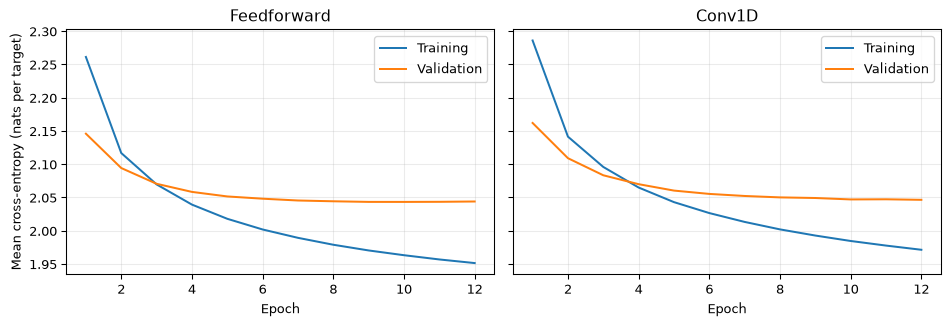

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, history, title in zip(
    axes, (mlp_history, cnn_history), ("Feedforward", "Conv1D")
):
    epochs = np.arange(1, len(history.history["loss"]) + 1)
    ax.plot(epochs, history.history["loss"], label="Training")
    ax.plot(epochs, history.history["val_loss"], label="Validation")
    ax.set(title=title, xlabel="Epoch")
    ax.legend()
    ax.grid(alpha=0.25)
axes[0].set_ylabel("Mean cross-entropy (nats per target)")
fig.tight_layout()
plt.show()

For a simple reference, a **bigram model** uses only the immediately
preceding character. We count adjacent token pairs in the training
examples and add one to every count, so unseen pairs still receive
positive probability. This baseline learns from the same training names
without a neural network.

The final table evaluates the two networks after the predeclared twelve
epochs. **Perplexity** is $\exp(J)$: a lower value indicates less
uncertainty under this loss. It is meaningful to compare these values
here because the models use identical tokens and test examples. It is
not a score for how convincing a generated name sounds.

In [10]:
bigram_counts = np.ones((VOCAB_SIZE, VOCAB_SIZE))
np.add.at(bigram_counts, (train_contexts[:, -1], y_train), 1)
bigram_probabilities = bigram_counts / bigram_counts.sum(axis=1, keepdims=True)
bigram_test_loss = -np.log(bigram_probabilities[test_contexts[:, -1], y_test]).mean()

test_losses = {"Bigram": bigram_test_loss}
for label, model in (("Feedforward", mlp), ("Conv1D", cnn)):
    test_losses[label] = model.evaluate(X_test, y_test, batch_size=BATCH_SIZE, verbose=0)

print(f"{'Model':<15} {'Test cross-entropy':>20} {'Perplexity':>12}")
for label, loss in test_losses.items():
    print(f"{label:<15} {loss:>20.3f} {np.exp(loss):>12.2f}")

Model             Test cross-entropy   Perplexity
Bigram                         2.449        11.57
Feedforward                    2.049         7.76
Conv1D                         2.051         7.77

## Does generation reproduce training names?

A generated spelling may be present in the training set, present only in
a held-out set, or absent from the corpus. Here we check only whether a
completed sample occurs in the training set. Being absent does not by
itself establish plausibility, originality outside this corpus, or
successful generalization. These small samples illustrate the
distinction rather than estimate a reliable novelty rate.

In [11]:
training_spellings = set(train_names)
for label, samples in (("Feedforward", mlp_samples), ("Conv1D", cnn_samples)):
    completed = [name for name, ended in samples if ended and name]
    reproduced = sum(name in training_spellings for name in completed)
    print(f"{label}: {reproduced} of {len(completed)} completed, nonempty samples "
          "occur in the training set")

Feedforward: 2 of 12 completed, nonempty samples occur in the training set
Conv1D: 4 of 12 completed, nonempty samples occur in the training set

## A concrete limit on memory

Both models see only the final eight characters of a sufficiently long
prefix. Two prefixes with identical final contexts must therefore
produce identical next-character distributions. Their earlier characters
cannot affect that prediction, regardless of training time or model
confidence.

In [12]:
prefix_a, prefix_b = "annamarie", "joannamarie"
print("Visible suffix:", prefix_a[-CONTEXT_LENGTH:])
for model in (mlp, cnn):
    difference = np.max(np.abs(next_probabilities(model, prefix_a)
                               - next_probabilities(model, prefix_b)))
    print(f"{model.name}: largest probability difference = {difference:.1e}")

Visible suffix: nnamarie
feedforward: largest probability difference = 0.0e+00
convolutional: largest probability difference = 0.0e+00

## What carries over to large language models?

The central mechanism carries over: tokens form contexts, a network
predicts next-token logits, cross-entropy trains those predictions, and
repeated sampling generates a continuation. A prompt supplies initial
tokens. During ordinary generation the learned parameters are fixed,
while the visible context changes.

Our toy model learns spelling patterns in a restricted corpus. Modern
autoregressive transformer language models use learned token
representations and attention to combine information within a much
larger context; their tokens often represent pieces of words. Their
scale, data, architecture, and subsequent instruction training support
capabilities that this experiment does not test. Understanding our
generator establishes the prediction-and-generation mechanism;
explaining attention and instruction-following requires additional
material.

## Experiments to try

1.  Change the context length to 3 or 5, restart the kernel, and rerun
    the training and sampling cells, skipping the final test-evaluation
    cell. Compare validation loss and samples before drawing
    conclusions. Changing context length also changes the parameter
    counts in these architectures.
2.  Generate several continuations of the same prefix. Explain why
    repeated sampling can produce different names from fixed parameters.
3.  Replace sampling with greedy decoding. Compare diversity and
    repeated outputs.
4.  Change the convolutional kernel width while keeping it no larger
    than the context. Predict the feature-map shape before running the
    model.

Use the validation set for these choices. Skip the cell that computes
the final test table while experimenting, then run it once after
deciding on settings. Repeated selection based on test results turns the
test set into another validation set.

## References

- Bengio, Y., Ducharme, R., Vincent, P., and Jauvin, C. (2003).
  <a href="https://www.jmlr.org/papers/v3/bengio03a.html" class="external"
  data-icon="true">A Neural Probabilistic Language Model</a>. *Journal
  of Machine Learning Research*, **3**, 1137–1155. The fixed-context
  feedforward approach and jointly learned word representations are
  developed in Section 2 and Figure 1.
- Karpathy, A.
  <a href="https://github.com/karpathy/makemore" class="external"
  data-icon="true">makemore</a>. Educational autoregressive names models
  and the source of our data. The dataset revision and checksum are
  specified in the loading cell above.